# EDA: CIFAR-10 (Kaggle verzija)

Istraživačka analiza podataka. Skup ima 50.000 označenih slika veličine 32x32 (RGB) u 10 klasa. Podaci se pripremaju skriptom `src/data.py`, a finalni test skup (10%) je izdvojen unapred stratifikovanim splitom sa fiksnim seed-om 42.

## 1. Učitavanje podataka
Učitavamo pripremljene nizove (`cifar10.npz`) i tabelu splita.

In [11]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

ROOT = Path("..")
OUT = ROOT / "results" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

d = np.load(ROOT / "data/processed/cifar10.npz")
X, y = d["X"], d["y"]
split = pd.read_csv(ROOT / "configs/split_seed42.csv")

print("X:", X.shape, X.dtype, "| y:", y.shape)
print("Raspon piksela:", X.min(), "-", X.max())

X: (50000, 32, 32, 3) uint8 | y: (50000,)
Raspon piksela: 0 - 255


## 2. Nedostajući podaci i osnovna provera

In [12]:
print("NaN u oznakama:", split.isna().sum().sum())
print("Jedinstvene klase:", sorted(np.unique(y)))
print("Broj slika po subsetu:")
print(split["subset"].value_counts())

NaN u oznakama: 0
Jedinstvene klase: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Broj slika po subsetu:
subset
trainval    45000
test         5000
Name: count, dtype: int64


**Zaključak:** u oznakama nema nedostajućih vrednosti, prisutno je svih 10 klasa (0 do 9), a podela je 45.000 slika za trening/validaciju i 5.000 za finalni test.

## 3. Distribucija klasa

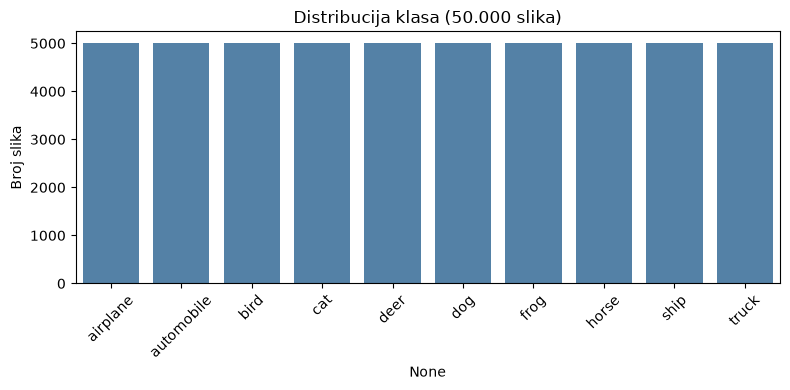

airplane      5000
automobile    5000
bird          5000
cat           5000
deer          5000
dog           5000
frog          5000
horse         5000
ship          5000
truck         5000
Name: count, dtype: int64


In [13]:
counts = pd.Series(y).value_counts().sort_index()
counts.index = CLASSES

plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, color="steelblue")
plt.title("Distribucija klasa (50.000 slika)")
plt.ylabel("Broj slika")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUT / "class_distribution.png", dpi=150)
plt.show()
print(counts)

**Zaključak:** skup je savršeno balansiran, svaka klasa ima tačno 5.000 slika. Zato je tačnost (accuracy) smislena glavna metrika i nije potrebno ponderisanje klasa.

## 4. Primeri slika po klasi

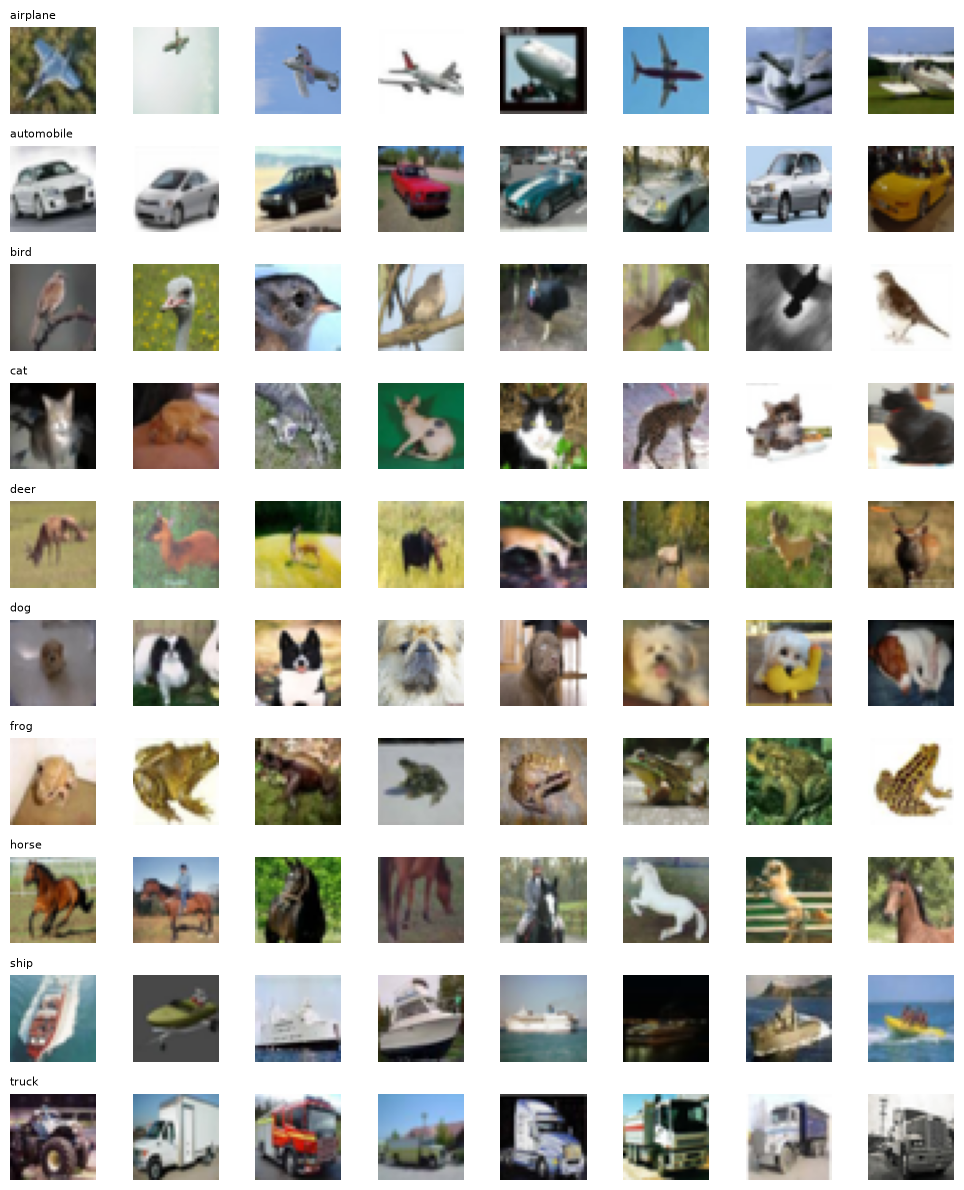

In [14]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(10, 8, figsize=(10, 12))
for c in range(10):
    idx = rng.choice(np.where(y == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X[i])
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc="left")
plt.tight_layout()
plt.savefig(OUT / "samples.png", dpi=150)
plt.show()

**Zaključak:** slike su veoma male (32x32), pa su neke teške i za ljudsko oko. Objekti su različito pozicionirani, uz raznovrsne pozadine i osvetljenje. Zato ima smisla probati augmentaciju (horizontalno okretanje, nasumično isecanje).

## 5. Statistika piksela (mean i std po RGB kanalu)
Ove vrednosti koristimo za normalizaciju u treningu i čuvamo ih u `configs/normalization.json`.

In [15]:
# Racunamo u float64: u float32 zbir saturira na 2**24 i mean ispadne pogresno (0.32768)
Xf = X.astype(np.float32) / 255.0
mean = X.astype(np.float64).mean(axis=(0, 1, 2)) / 255.0
std = (X.astype(np.float64) / 255.0).std(axis=(0, 1, 2))
print("Mean (R,G,B):", mean)
print("Std  (R,G,B):", std)

# Provera ispravnosti: kanali ne smeju imati identicnu srednju vrednost
assert not np.allclose(mean, mean[0]), "Mean je isti za sve kanale, proveri racunanje"

# Cuvamo za normalizaciju u treningu
with open(ROOT / "configs/normalization.json", "w") as f:
    json.dump({"mean": mean.tolist(), "std": std.tolist()}, f, indent=2)

Mean (R,G,B): [0.49139968 0.48215841 0.44653091]
Std  (R,G,B): [0.24703223 0.24348513 0.26158784]


**Zaključak:** mean i std se računaju po kanalu na celom skupu i koriste za normalizaciju ulaza. Računanje je rađeno u float64, jer u float32 zbir saturira i daje pogrešan rezultat.

## 6. Histogrami intenziteta po kanalima

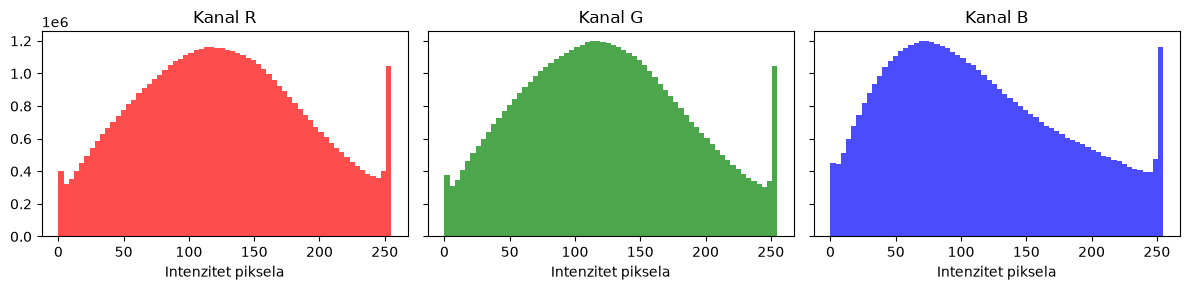

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for k, (name, col) in enumerate(zip("RGB", ["red", "green", "blue"])):
    ax[k].hist(X[..., k].ravel(), bins=64, color=col, alpha=0.7)
    ax[k].set_title(f"Kanal {name}")
    ax[k].set_xlabel("Intenzitet piksela")
plt.tight_layout()
plt.savefig(OUT / "pixel_histograms.png", dpi=150)
plt.show()

**Zaključak:** crveni i zeleni kanal imaju približno zvonastu raspodelu oko srednjih vrednosti, a plavi je nagnut ka tamnijim vrednostima. Na svim kanalima postoji izražen skok na vrednosti 255, što ukazuje na dosta potpuno svetlih (zasićenih) piksela, verovatno u pozadinama kao što su nebo ili belina.

## 7. Korelacija kanala i svetlina po klasi

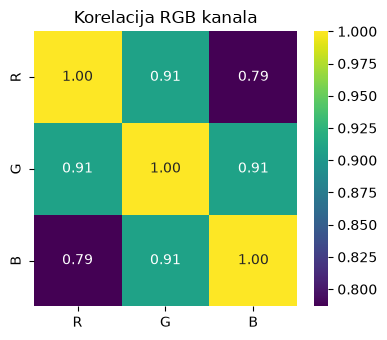

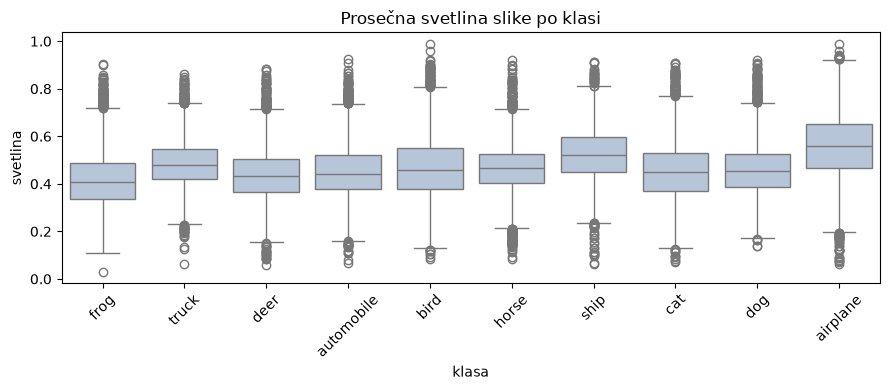

In [17]:
sub = Xf[:5000].reshape(-1, 3)
corr = np.corrcoef(sub.T)
plt.figure(figsize=(4, 3.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis",
            xticklabels=list("RGB"), yticklabels=list("RGB"))
plt.title("Korelacija RGB kanala")
plt.tight_layout()
plt.savefig(OUT / "channel_correlation.png", dpi=150)
plt.show()

bright = Xf.mean(axis=(1, 2, 3))
df = pd.DataFrame({"klasa": [CLASSES[i] for i in y], "svetlina": bright})
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="klasa", y="svetlina", color="lightsteelblue")
plt.xticks(rotation=45)
plt.title("Prosečna svetlina slike po klasi")
plt.tight_layout()
plt.savefig(OUT / "brightness_by_class.png", dpi=150)
plt.show()

**Zaključak:** RGB kanali su jako korelisani (R-G 0,91, G-B 0,91, R-B 0,79), što je očekivano za prirodne slike. Prosečna svetlina se razlikuje po klasama: avioni i brodovi su u proseku najsvetliji (verovatno zbog neba i vode), a žabe najtamnije. To znači da svetlina nosi deo informacije o klasi, a da se model ne bi previše oslanjao na nju, može pomoći augmentacija (npr. promena svetline).

## 8. Provera duplikata

In [18]:
import hashlib
hashes = [hashlib.md5(X[i].tobytes()).hexdigest() for i in range(len(X))]
n_dup = len(hashes) - len(set(hashes))
print("Tačnih duplikata slika:", n_dup)

Tačnih duplikata slika: 0


**Zaključak:** nema tačnih duplikata slika (0), pa nema opasnosti da ista slika završi i u trening i u validacionom skupu.

## 9. Provera stratifikacije splita

In [19]:
tab = pd.crosstab(split["subset"], split["label"], normalize="index")
print((tab * 100).round(2))

label     airplane  automobile  bird   cat  deer   dog  frog  horse  ship  \
subset                                                                      
test          10.0        10.0  10.0  10.0  10.0  10.0  10.0   10.0  10.0   
trainval      10.0        10.0  10.0  10.0  10.0  10.0  10.0   10.0  10.0   

label     truck  
subset           
test       10.0  
trainval   10.0  


**Zaključak:** u trainval i test skupu svaka klasa čini tačno 10%, što potvrđuje da je stratifikacija ispravna.

## Sažetak

- Skup je ispravan: nema nedostajućih vrednosti, duplikata ni oštećenih slika, a sve slike su 32x32x3.
- Klase su savršeno balansirane (5.000 po klasi), a split 90/10 je stratifikovan i reproduktivan (seed 42).
- Ulazi se normalizuju sa mean/std po kanalu iz `configs/normalization.json`.
- Kanali su jako korelisani, a klase se razlikuju i po svetlini, pa je za generalizaciju korisna augmentacija.